# Learning from Consequences

*The Mathematics of Machine Intelligence · Chapter 14*

Revise a forecast by the gap between what you expected and what you got.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the forecast, the outcome, what follows the situation, and the learning rate. Then choose the matching card: the prediction error and update for a single forecast, the chain card when value must travel back to an earlier cue, the blocking card when a new cue arrives with an outcome that is already predicted, the Q-learning card when the learner chooses actions, the overestimation card when it picks the best-looking estimate, and the score card when comparing a game score with random play and a human tester. State that a reward is a number the task supplies and that a good update rule does not solve exploration or say whether the score counts what a person wants.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 14, Learning from Consequences: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def td_error(reward, value_now, value_next=0.0, gamma=1.0):
    """delta = r + gamma V(next) - V(now)."""
    return reward + gamma * value_next - value_now

def value_update(value_now, error, alpha):
    return value_now + alpha * error

def td_picture(forecast=0.0, reward=1, alpha=0.5):
    delta = td_error(reward, forecast)
    new = value_update(forecast, delta, alpha)
    fig, ax = panels()
    labels = ['forecast\nbefore', 'reward\nreceived', 'prediction\nerror', 'forecast\nafter']
    heights = [forecast, reward, delta, new]
    colours = [GREY, GOLD, TERRA if delta < -1e-12 else TEAL, NAVY]
    bars = ax[0].bar(labels, heights, color=colours, width=0.6)
    ax[0].axhline(0, color=NAVY, linewidth=1)
    for bar, h in zip(bars, heights):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + (0.07 if h >= 0 else -0.07), sig(h), va='bottom' if h >= 0 else 'top')
    ax[0].set(ylabel='size (drops of juice)', title='Reward, error and the revised forecast', ylim=(-1.35, 2.2))
    grid = np.linspace(0, 1.2, 50)
    for r, colour, style in [(1, TEAL, 'solid'), (0, TERRA, 'dashed')]:
        chosen = r == reward
        ax[1].plot(grid, [td_error(r, v) for v in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'reward {r}')
    ax[1].axhline(0, color=GREY, linewidth=1, linestyle='dotted')
    ring(ax[1], forecast, delta)
    ax[1].set(xlabel='forecast just before the reward', ylabel='prediction error', title='Better than forecast is positive', ylim=(-1.35, 1.35))
    ax[1].legend(fontsize=9, loc='lower left')
    if delta > 1e-12:
        sign = 'positive (burst-like)'
    elif delta < -1e-12:
        sign = 'negative (dip-like)'
    else:
        sign = 'zero (no change)'
    metrics = {'Prediction error': sig(delta), 'Sign': sign, 'Forecast after the update': sig(new), 'Forecast moves by': sig(new - forecast)}
    summary = f'The learner forecast {sig(forecast)} and received {sig(reward)}, so the error is {sig(delta)}, which is {sign}. With learning rate {alpha:g} the forecast moves by {sig(alpha * delta)} to {sig(new)}, not all the way to the outcome.'
    calc = f'delta = r + gamma x V(next) - V(now) = {sig(reward)} + 0 - {sig(forecast)} = {sig(delta)}, because the task ends after the reward and nothing more is forecast. V(new) = V(old) + alpha x delta = {sig(forecast)} + {alpha:g} x {sig(delta)} = {sig(new)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
N_CUES = 6

def credit_run(alpha, lam, trials=8, cues=N_CUES):
    """Values of the cues after each trial: gamma 1, one reward after the last cue.

    Every cue is updated from the errors computed with the values held at the start of the
    trial. lam = 0 is the plain method; lam = 1 lets a trace last through all the cues.
    Returns an array of shape (trials + 1, cues); row 0 is the starting values.
    """
    values = np.zeros(cues)
    history = [values.copy()]
    for _ in range(trials):
        ahead = np.append(values[1:], 0.0)
        reward = np.zeros(cues)
        reward[-1] = 1.0
        errors = reward + ahead - values
        change = np.zeros(cues)
        for i in range(cues):
            change[i] = alpha * sum((lam ** (k - i) * errors[k] for k in range(i, cues)))
        values = values + change
        history.append(values.copy())
    return np.array(history)

def first_trial_positive(history, cue):
    positive = np.nonzero(history[:, cue] > 1e-12)[0]
    return int(positive[0]) if len(positive) else None

def cell_text(v):
    return '0' if abs(v) < 1e-12 else f'{v:.2g}'

def credit_picture(alpha=1.0, lam=0.0):
    history = credit_run(alpha, lam)
    trials = history.shape[0] - 1
    fig, ax = panels()
    ax[0].imshow(history[1:], cmap='Blues', vmin=0, vmax=1.4, aspect='auto')
    for t in range(trials):
        for c in range(N_CUES):
            v = history[t + 1, c]
            ax[0].text(c, t, cell_text(v), ha='center', va='center', fontsize=8, color='white' if v > 0.6 else NAVY)
    ax[0].set_xticks(range(N_CUES), [str(c + 1) for c in range(N_CUES)])
    ax[0].set_yticks(range(trials), [str(t + 1) for t in range(trials)])
    ax[0].set(xlabel='cue (the reward follows cue 6)', ylabel='trial', title='Value of each cue after each trial')
    ax[0].grid(False)
    for other, colour, style in [(0.0, GREY, 'dotted'), (0.5, TEAL, 'dashed'), (1.0, TERRA, 'solid')]:
        run = credit_run(alpha, other)
        chosen = other == lam
        ax[1].plot(range(trials + 1), run[:, 0], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'trace {other:g}')
    first = first_trial_positive(history, 0)
    if first is not None:
        ring(ax[1], first, history[first, 0])
    ax[1].set(xlabel='trial', ylabel='value of cue 1', title='How soon the first cue gains value', ylim=(-0.04, 1.08))
    ax[1].legend(fontsize=9, loc='lower right', title='trace length', title_fontsize=9)
    first_text = f'trial {first}' if first is not None else 'not within 8 trials'
    metrics = {'Cue 1 first gains value': first_text, 'Cue 6 after trial 1': sig(history[1, 5]), 'Cue 1 after trial 1': sig(history[1, 0]), 'Cue 1 after 8 trials': sig(history[8, 0])}
    summary = f'With learning rate {alpha:g} and trace {lam:g}, cue 1 first gains value on {first_text}. ' + ('The trace lets one reward credit every cue at once.' if lam >= 1 else 'Without a full trace, value creeps back about one cue per trial.')
    calc = f'Each cue is updated from the cue after it, using the values held at the start of the trial: error = reward + value of the next cue - value of this cue. Cue 6 gets reward 1 and no next cue. Trial 1 gives cue 6 value {sig(history[1, 5])} and cue 1 value {sig(history[1, 0])}; trace {lam:g} passes on the later errors scaled by {lam:g} per cue.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
OUTCOME = 1.0
COMPOUND_TRIALS = 8

def rescorla_wagner(preliminary, rate, compound_trials=COMPOUND_TRIALS):
    """Noise alone for `preliminary` trials, then noise plus light. Returns strength histories."""
    noise, light = (0.0, 0.0)
    noise_h, light_h = ([0.0], [0.0])
    for _ in range(preliminary):
        noise += rate * (OUTCOME - noise)
        noise_h.append(noise)
        light_h.append(light)
    for _ in range(compound_trials):
        gap = OUTCOME - (noise + light)
        noise += rate * gap
        light += rate * gap
        noise_h.append(noise)
        light_h.append(light)
    return (np.array(noise_h), np.array(light_h))

def blocking_picture(preliminary=8, rate=0.2):
    noise_b, light_b = rescorla_wagner(preliminary, rate)
    _, light_a = rescorla_wagner(0, rate)
    gap = OUTCOME - noise_b[preliminary]
    fig, ax = panels()
    total = preliminary + COMPOUND_TRIALS
    x = np.arange(total + 1)
    ax[0].plot(x, noise_b, color=TEAL, linewidth=2, label='noise strength')
    ax[0].plot(x, light_b, color=TERRA, linewidth=3, label='light strength')
    xa = np.concatenate([np.arange(preliminary + 1), preliminary + np.arange(1, COMPOUND_TRIALS + 1)])
    ya = np.concatenate([np.zeros(preliminary + 1), light_a[1:]])
    ax[0].plot(xa, ya, color=GOLD, linewidth=2, linestyle='dashed', label='light, no earlier noise trials')
    if preliminary:
        ax[0].axvline(preliminary, color=GREY, linestyle='dotted', linewidth=1)
        tag(ax[0], preliminary, 1.12, 'light added', fontsize=9, color=GREY)
    ax[0].set(xlabel='trial', ylabel='associative strength', title='Noise first, then noise plus light', ylim=(-0.03, 1.2))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    counts = np.arange(0, 17)
    for other, colour, style in [(0.1, GREY, 'dotted'), (0.2, TEAL, 'solid'), (0.4, TERRA, 'dashed')]:
        curve = [rescorla_wagner(int(n), other)[1][-1] for n in counts]
        chosen = other == rate
        ax[1].plot(counts, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'rate {other:g}')
    ring(ax[1], preliminary, light_b[-1])
    ax[1].set(xlabel='noise-alone trials before the light', ylabel='light strength after 8 pairings', title='A predicted outcome blocks the light', ylim=(-0.02, 0.62))
    ax[1].legend(fontsize=9, loc='upper right')
    together = light_a[-1]
    metrics = {'Light strength after 8 pairings': sig(light_b[-1]), 'Same, light and noise learned together': sig(together), 'Gap left for learning at the first pairing': sig(gap), 'Light as a share of the together value': sig(light_b[-1] / together)}
    summary = f'After {preliminary} noise-alone trials the noise holds strength {sig(noise_b[preliminary])}, leaving a gap of {sig(gap)} for the light to learn from. After 8 pairings the light has strength {sig(light_b[-1])}, against {sig(together)} when light and noise were learned together.'
    calc = f'Each cue present gains rate x (1 - combined strength) = {rate:g} x gap per trial. Noise alone: strength = 1 - (1 - {rate:g})^{preliminary} = {sig(noise_b[preliminary])}. First pairing gap = {sig(gap)}. Light after 8 pairings = gap x (1 - (1 - 2 x {rate:g})^8) / 2 = {sig(light_b[-1])}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
Q_OLD, REWARD, Q_NEXT_BEST = (2.0, 1.0, 3.0)

def q_update(q_old, reward, best_next, alpha, gamma, ends_task=False):
    target = reward + (0.0 if ends_task else gamma * best_next)
    return {'target': target, 'error': target - q_old, 'new': q_old + alpha * (target - q_old)}

def q_picture(alpha=0.5, gamma=0.9, ends_task=0):
    data = q_update(Q_OLD, REWARD, Q_NEXT_BEST, alpha, gamma, bool(ends_task))
    fig, ax = panels()
    heights = [Q_OLD, data['target'], data['new']]
    bars = ax[0].bar(['old estimate', 'target', 'new estimate'], heights, color=[GREY, GOLD, NAVY], width=0.55)
    for bar, h in zip(bars, heights):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + 0.08, sig(h), va='bottom')
    ax[0].set(ylabel='value of moving left', title='The estimate moves partway to the target', ylim=(0, 4.6))
    grid = np.linspace(0, 1, 101)
    for g, colour, style in [(0.0, GREY, 'dotted'), (0.5, TEAL, 'dashed'), (0.9, TERRA, 'solid')]:
        chosen = g == gamma
        curve = [q_update(Q_OLD, REWARD, Q_NEXT_BEST, a, g, bool(ends_task))['new'] for a in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'discount {g:g}')
    ring(ax[1], alpha, data['new'])
    ax[1].axhline(Q_OLD, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 0.8, Q_OLD + 0.06, 'old estimate 2', fontsize=9, color=GREY, va='bottom')
    ax[1].set(xlabel='learning rate (alpha)', ylabel='new estimate', title='A bigger step lands nearer the target', ylim=(0.8, 4.0))
    ax[1].legend(fontsize=9, loc='upper left')
    end_text = 'the next situation ends the task, so its term is zero' if ends_task else f'best next value {Q_NEXT_BEST:g} is counted'
    metrics = {'Target': sig(data['target']), 'Gap, target minus estimate': sig(data['error']), 'New estimate': sig(data['new']), 'Share of the gap closed': sig(alpha)}
    summary = f"The target is {sig(data['target'])} ({end_text}), so the estimate of 2 moves a share {alpha:g} of the gap {sig(data['error'])} to {sig(data['new'])}. A learning rate of 1 would jump all the way to the target."
    if ends_task:
        calc = f"Target = r = {REWARD:g}, since nothing follows. New = {Q_OLD:g} + {alpha:g} x ({sig(data['target'])} - {Q_OLD:g}) = {sig(data['new'])}."
    else:
        calc = f"Target = r + gamma x max Q(next) = {REWARD:g} + {gamma:g} x {Q_NEXT_BEST:g} = {sig(data['target'])}. New = {Q_OLD:g} + {alpha:g} x ({sig(data['target'])} - {Q_OLD:g}) = {sig(data['new'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
_GRID = np.linspace(-9.0, 9.0, 36001)
_PDF = np.exp(-0.5 * _GRID ** 2) / math.sqrt(2 * math.pi)
_CDF = None

def _normal_cdf_table():
    global _CDF
    if _CDF is None:
        _CDF = 0.5 * (1.0 + np.array([math.erf(v / math.sqrt(2)) for v in _GRID]))
    return _CDF

def expected_max_standard_normal(n):
    """Mean of the largest of n independent standard normal draws, by numerical integration."""
    if n < 1:
        raise ValueError('Need at least one action.')
    cdf = _normal_cdf_table()
    integrand = _GRID * n * _PDF * cdf ** (n - 1)
    step = _GRID[1] - _GRID[0]
    return float(np.sum(integrand) * step)

def overestimate_picture(n_actions=8, noise_sd=1.0):
    n = int(n_actions)
    e_n = expected_max_standard_normal(n)
    expected = noise_sd * e_n
    rng = np.random.default_rng(14)
    draws = rng.normal(0.0, noise_sd, n)
    best = int(np.argmax(draws))
    fig, ax = panels()
    x = np.arange(1, n + 1)
    ax[0].axhline(0, color=GREY, linewidth=1.5)
    tag(ax[0], 0.5 + n / 2, -4.35, 'grey line: true value of every action, 0', fontsize=9, color=GREY, va='bottom')
    ax[0].plot(x, draws, linestyle='none', marker='o', markersize=7, color=TEAL, label='one round of estimates')
    ring(ax[0], x[best], draws[best])
    ax[0].axhline(expected, color=TERRA, linestyle='dashed', linewidth=2, label='average best-looking estimate')
    ax[0].set(xlabel='action', ylabel='estimated value', title='Equal actions, noisy estimates (seed 14)', xlim=(0.4, n + 0.6), ylim=(-4.6, 4.6))
    if n <= 8:
        ax[0].set_xticks(x)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    counts = np.arange(1, 17)
    table = [expected_max_standard_normal(int(k)) for k in counts]
    for sd, colour, style in [(0.5, GREY, 'dotted'), (1.0, TEAL, 'dashed'), (2.0, TERRA, 'solid')]:
        chosen = sd == noise_sd
        ax[1].plot(counts, [sd * t for t in table], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'estimate noise sd {sd:g}')
    ring(ax[1], n, expected)
    ax[1].set(xlabel='number of equally good actions', ylabel='average overestimate', title='More options, more overestimate', ylim=(-0.1, 4.7))
    ax[1].set_xticks([1, 4, 8, 12, 16])
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Average best-looking estimate': sig(expected), 'True value of the action it picks': '0', 'Overestimate in units of the noise sd': sig(e_n), "This round's best-looking estimate": sig(draws[best])}
    summary = f'With {n} equally good actions and estimate noise sd {noise_sd:g}, the best-looking one is overestimated by {sig(expected)} on average, though the estimates themselves are unbiased. The upward bias comes from picking the maximum of noisy numbers, and it grows with the number of options.'
    calc = f'Average of the largest of {n} standard normal draws = {sig(e_n)} (numerical integration of x n phi(x) Phi(x)^(n-1)). Times noise sd {noise_sd:g} = {sig(expected)}. For 2 actions the exact value is sd / sqrt(pi) = {sig(noise_sd / math.sqrt(math.pi))}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
RANDOM_SCORE, NETWORK_SCORE, HUMAN_SCORE = (65.2, 328.3, 4335.0)
THRESHOLD_SHARE = 0.75

def gain_share(score, random_score=RANDOM_SCORE, human_score=HUMAN_SCORE):
    """The score's gain over random play as a fraction of the human tester's gain."""
    if human_score <= random_score:
        raise ValueError('The human score must exceed random play.')
    return (score - random_score) / (human_score - random_score)

def score_for_share(share, random_score=RANDOM_SCORE, human_score=HUMAN_SCORE):
    return random_score + share * (human_score - random_score)

def frostbite_picture(score=NETWORK_SCORE):
    share = gain_share(score)
    need = score_for_share(THRESHOLD_SHARE)
    fig, ax = panels()
    labels = ['random play', 'this score', 'human tester']
    values = [RANDOM_SCORE, score, HUMAN_SCORE]
    bars = ax[0].barh(labels, values, color=[GREY, NAVY, GOLD], height=0.55)
    for bar, v in zip(bars, values):
        ax[0].text(v + 80, bar.get_y() + bar.get_height() / 2, sig(v, 4), va='center', fontsize=10, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9})
    ax[0].axvline(need, color=TERRA, linestyle='dashed', linewidth=1.8)
    tag(ax[0], need - 60, 2.48, 'score needed for\n75 percent of the gain', fontsize=9, color=TERRA, ha='right', va='center')
    ax[0].invert_yaxis()
    ax[0].set(xlabel='Frostbite game score', title='Scores on one game', xlim=(0, 5300), ylim=(2.9, -0.55))
    grid = np.linspace(0, 4600, 300)
    ax[1].plot(grid, [100 * gain_share(g) for g in grid], color=TEAL, linewidth=2.5)
    ax[1].axhline(75, color=TERRA, linestyle='dashed', linewidth=1.5)
    ax[1].plot([NETWORK_SCORE], [100 * gain_share(NETWORK_SCORE)], marker='v', markersize=9, color=GOLD, linestyle='none', label='the 2015 network')
    ring(ax[1], score, 100 * gain_share(score))
    ax[1].text(250, 78, '75 percent line', fontsize=9, color=TERRA, va='bottom')
    ax[1].set(xlabel='Frostbite game score', ylabel='share of the human gain (percent)', title='Gain over random play, as a share', ylim=(-6, 106))
    ax[1].legend(fontsize=9, loc='lower right')
    reached = 'yes' if share >= THRESHOLD_SHARE - 1e-12 else 'no'
    metrics = {'Gain over random play': sig(score - RANDOM_SCORE, 4), 'Human gain over random play': sig(HUMAN_SCORE - RANDOM_SCORE, 5), 'Share of the human gain (percent)': sig(100 * share), 'Reaches 75 percent': reached}
    if score == NETWORK_SCORE:
        who = "The 2015 network's"
    else:
        who = 'A hypothetical'
    summary = f"{who} Frostbite score of {sig(score, 4)} is a gain of {sig(score - RANDOM_SCORE, 4)} over random play, {sig(100 * share)} percent of the human tester's {sig(HUMAN_SCORE - RANDOM_SCORE, 5)}. Reaching 75 percent on this game takes a score of {sig(need, 4)}."
    calc = f'Gain = {sig(score, 4)} - {RANDOM_SCORE:g} = {sig(score - RANDOM_SCORE, 4)}. Human gain = {HUMAN_SCORE:g} - {RANDOM_SCORE:g} = {sig(HUMAN_SCORE - RANDOM_SCORE, 5)}. Share = {sig(score - RANDOM_SCORE, 4)} / {sig(HUMAN_SCORE - RANDOM_SCORE, 5)} = {sig(share, 4)}. Score for 75 percent = {RANDOM_SCORE:g} + 0.75 x {sig(HUMAN_SCORE - RANDOM_SCORE, 5)} = {sig(need, 6)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REWARDS = np.arange(1, 8)
DISTRIBUTIONS = {'equal chances': np.full(7, 1 / 7), 'small rewards likelier': np.array([0.3, 0.25, 0.18, 0.12, 0.08, 0.05, 0.02]), 'large rewards likelier': np.array([0.02, 0.05, 0.08, 0.12, 0.18, 0.25, 0.3])}

def expectile(tau, probs, rewards=REWARDS):
    """The value v where tau E[(r - v)+] = (1 - tau) E[(v - r)+]; found by bisection."""
    if not 0 < tau < 1:
        raise ValueError('tau must be strictly between 0 and 1.')
    lo, hi = (float(min(rewards)), float(max(rewards)))
    for _ in range(200):
        mid = (lo + hi) / 2
        balance = tau * np.sum(probs * np.maximum(rewards - mid, 0)) - (1 - tau) * np.sum(probs * np.maximum(mid - rewards, 0))
        if balance > 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

def run_channel(tau, probs, trials=1500, step=0.02, start=4.0, seed=14):
    """A channel that moves up by step x tau x error after good news and down by step x (1 - tau) x error after bad news."""
    rng = np.random.default_rng(seed)
    draws = rng.choice(REWARDS, size=trials, p=probs)
    v = start
    trace = [v]
    for r in draws:
        error = r - v
        v += step * (tau if error > 0 else 1 - tau) * error
        trace.append(v)
    return np.array(trace)

def channel_picture(tau=0.5, distribution='equal chances'):
    probs = DISTRIBUTIONS[distribution]
    v = expectile(tau, probs)
    mean = float(np.sum(probs * REWARDS))
    trace = run_channel(tau, probs)
    settled = float(np.mean(trace[-500:]))
    fig, ax = panels()
    ax[0].plot(trace, color=TEAL, linewidth=1.2, label="channel's forecast (one seeded run)")
    ax[0].axhline(v, color=NAVY, linestyle='dashed', linewidth=2, label='exact reversal point')
    ax[0].set(xlabel='reward delivered (trial)', ylabel='forecast = reversal point', title=f'A channel with optimism {tau:g} (seed 14)', ylim=(0.5, 7.5))
    ax[0].set_yticks(range(1, 8))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    grid = np.linspace(0.05, 0.95, 46)
    for name, colour, style in [('equal chances', TEAL, 'solid'), ('small rewards likelier', TERRA, 'dashed'), ('large rewards likelier', GOLD, 'dotted')]:
        chosen = name == distribution
        ax[1].plot(grid, [expectile(t, DISTRIBUTIONS[name]) for t in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=name)
    for r in REWARDS:
        ax[1].axhline(r, color=GREY, linewidth=0.7, alpha=0.5)
    ring(ax[1], tau, v)
    ax[1].set(xlabel='optimism of the channel (weight on good news)', ylabel='reversal point (reward size)', title='More optimistic means a higher reversal point', ylim=(0.6, 7.4))
    ax[1].set_yticks(range(1, 8))
    ax[1].legend(fontsize=8, loc='lower right')
    k = int(math.floor(v))
    between = f'{k} and {k + 1}'
    metrics = {'Reversal point (exact)': sig(v), 'Falls between reward sizes': between, 'Average reward': sig(mean), 'Last 500 trials of the run': sig(settled)}
    summary = f'A channel that weighs good news {tau:g} and bad news {sig(1 - tau)} settles where rewards above its forecast and below it balance, at {sig(v)}. Rewards larger than {sig(v)} give it a positive error and smaller ones a negative error, so its reversal point sits between sizes {between}.'
    calc = f'The forecast stops moving when {tau:g} x E[(r - v) above zero] = {sig(1 - tau)} x E[(v - r) above zero]. Solving gives v = {sig(v)}. The seeded run averaged {sig(settled)} over its last 500 trials. At optimism 0.5 the point is the average reward, {sig(mean)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C14-D01: How much should a surprise change a forecast?

A monkey that has learned a light predicts juice gets juice, or does not. What is the prediction error, and how far does the forecast move?

The forecast before the reward is what the learner expected. The error compares it with what came, plus whatever the learner forecasts afterwards. A positive error says things went better than forecast, a negative one worse, and zero means the forecast was right. The update then moves the forecast a share alpha of the way, so one outcome does not become the whole truth.

$$
\delta_t=r_{t+1}+\gamma V(S_{t+1})-V(S_t),\qquad V_{\mathrm{new}}(S_t)=V_{\mathrm{old}}(S_t)+\alpha\delta_t
$$

**Symbols:** delta: prediction error: reward plus discounted next forecast, minus the forecast held before; r: the reward received, in drops of juice; V: a forecast of the rewards to come from a situation; gamma: the discount on later rewards; here nothing follows the juice, so it drops out; alpha: learning rate, between zero and one

**Predict before looking:** The light has taught a forecast of 1. Predict the error when juice arrives, when it fails, and when juice arrives with no light, then check each against the controls.

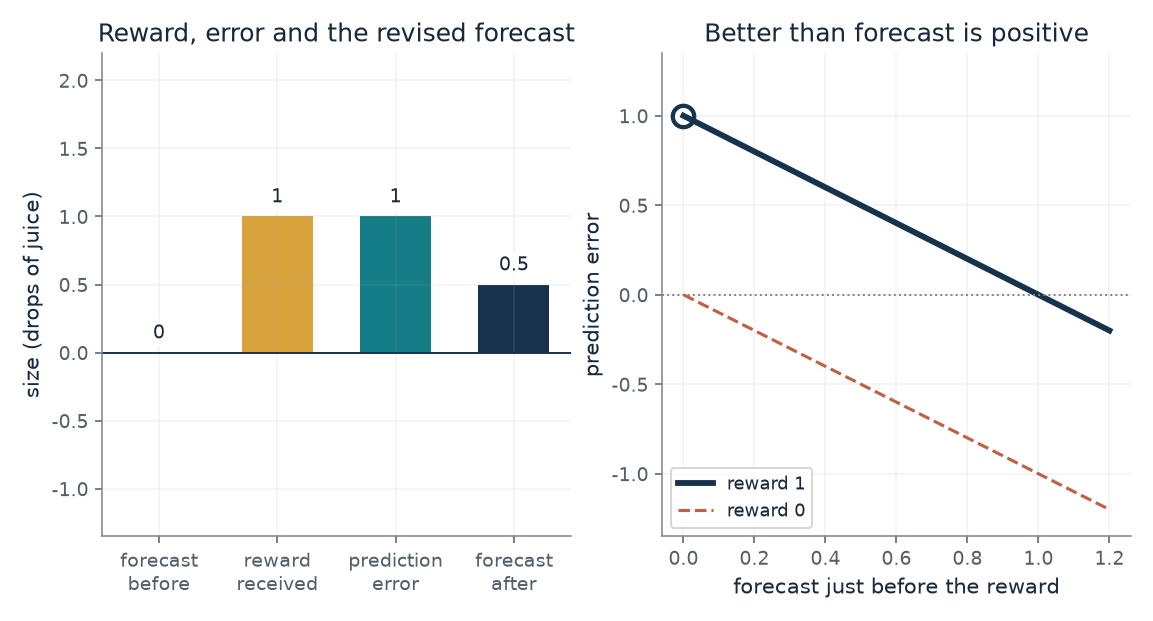

- **Prediction error:** 1
- **Sign:** positive (burst-like)
- **Forecast after the update:** 0.5
- **Forecast moves by:** 0.5

The learner forecast 0 and received 1, so the error is 1, which is positive (burst-like). With learning rate 0.5 the forecast moves by 0.5 to 0.5, not all the way to the outcome.

delta = r + gamma x V(next) - V(now) = 1 + 0 - 0 = 1, because the task ends after the reward and nothing more is forecast. V(new) = V(old) + alpha x delta = 0 + 0.5 x 1 = 0.5.

In [2]:
figure, values, explanation = td_picture(**{'forecast': 0.0, 'reward': 1, 'alpha': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much should a surprise change a forecast?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Forecast before the reward = 0.4, Reward received (drops) = 1, Learning rate (alpha) = 0.5: A forecast of 0.4 and an outcome of 1 give an error of 0.6, and the forecast moves halfway at rate 0.5 to 0.7. Set the forecast to 1 and the reward to 1 to see the error vanish, and the reward to 0 to see it turn negative.

**Takeaway:** The error is the gap between what arrived and what was forecast; the forecast moves by a share of that gap and stops moving when the gap is zero.

**Why it matters:** A learner that corrects itself by the size and sign of its surprise needs no teacher to say what the right forecast was. When nothing is surprising, nothing changes.

**In brains and behavior:** The 1997 review set recordings of monkey dopamine cells beside this error: a burst at surprise juice, none at expected juice, a dip when expected juice failed. The match is in sign and timing only, and the book names a mismatch (early juice).

**In machines:** A learner computes the error explicitly and applies the update. A reward here is a number supplied by the task, not a claim that the machine feels pleasure.

**Where it applies:** The task ends after the reward, so the next situation is worth zero. The error is a number in a model; the book says it has no real units and cannot be compared with spike counts. A reward is a number the task supplies, not pleasure.

**Check your understanding:** The forecast is 0.5, the reward is 1, and alpha is 0.5. What are the error and the new forecast?

<details><summary>Show the answer</summary>

The error is 1 - 0.5 = 0.5, and the new forecast is 0.5 + 0.5 x 0.5 = 0.75.

</details>

*Source: Chapter 14, Dopamine cells burst at surprise juice and dipped when juice failed. Book formulas and the chapter's illustrative numbers: forecast 1 with juice gives 0, no juice gives minus 1, juice with no forecast gives plus 1, and the constructed forecast 0.4, outcome 1, rate 0.5 gives 0.7. The recordings behind the dopamine comparison are the 1997 review's Figure 1, which the book redraws as a schematic with no values.*

## C14-D02: How does credit travel back from the juice to the light?

If a reward follows the sixth of six cues, how many trials pass before the first cue gains value?

On the first trial only the last cue sees a reward, so only it gains value. On the next trial the fifth cue is followed by a cue that is now worth something, so it gains, and so on back to cue 1. A trace carries each error to the earlier cues in the same trial, so the whole chain learns together.

$$
\delta_k=r_{k+1}+V(S_{k+1})-V(S_k),\qquad \Delta V(S_i)=\alpha\sum_{k\ge i}\lambda^{\,k-i}\,\delta_k
$$

**Symbols:** delta_k: the error at cue k, from values held at the start of the trial; lambda: how far a trace carries later errors back to earlier cues (0 is the plain method, 1 lasts through all six); alpha: learning rate; V: the value of a cue

**Predict before looking:** With the plain method (trace 0) and learning rate 1, predict the trial on which cue 1 first gains value, and what a trace through all six changes.

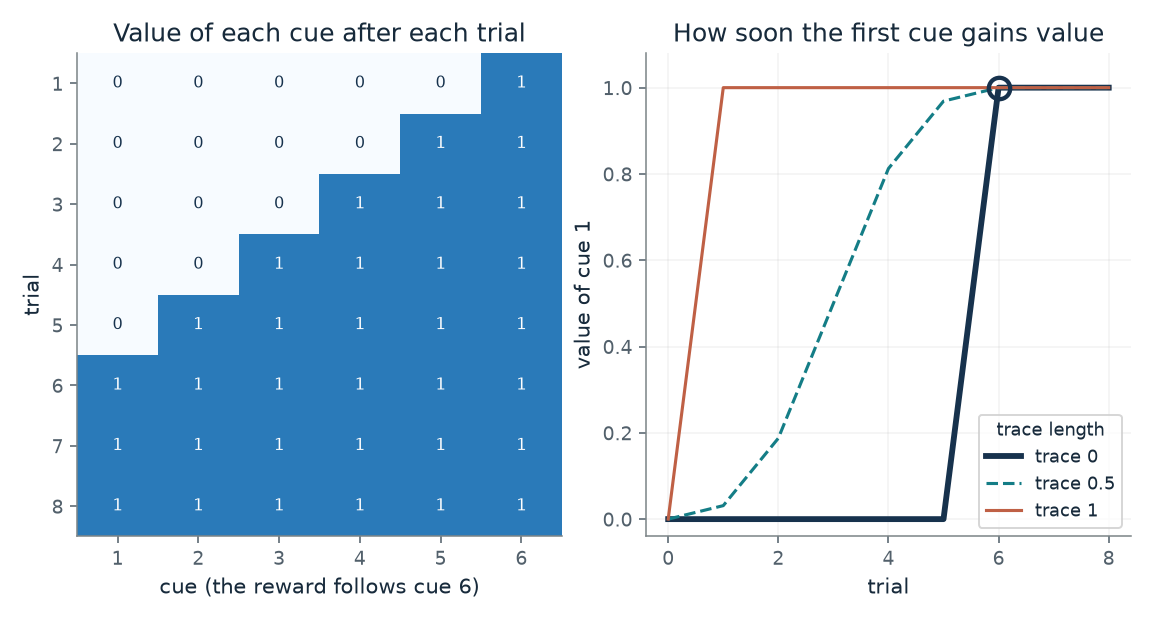

- **Cue 1 first gains value:** trial 6
- **Cue 6 after trial 1:** 1
- **Cue 1 after trial 1:** 0
- **Cue 1 after 8 trials:** 1

With learning rate 1 and trace 0, cue 1 first gains value on trial 6. Without a full trace, value creeps back about one cue per trial.

Each cue is updated from the cue after it, using the values held at the start of the trial: error = reward + value of the next cue - value of this cue. Cue 6 gets reward 1 and no next cue. Trial 1 gives cue 6 value 1 and cue 1 value 0; trace 0 passes on the later errors scaled by 0 per cue.

In [3]:
figure, values, explanation = credit_picture(**{'lam': 0.0, 'alpha': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does credit travel back from the juice to the light?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Trace length (lambda) = 1.0, Learning rate (alpha) = 1.0: A trace that lasts through all six cues gives every cue its value on trial 1. Return the trace to 0 to see the plain method: only cue 6 gains on trial 1, and cue 1 waits until trial 6.

**Takeaway:** Bootstrapping passes value back one cue per trial; a trace lets one reward credit the whole chain at once.

**Why it matters:** The earliest event that reliably predicts a reward is the one worth reacting to. A learner finds it by correcting each forecast with the next, without waiting to see the final reward in every case.

**In brains and behavior:** In monkeys learning a light-and-lever task, fewer cells burst at the juice and more at the light as training went on. That is a population average, and it does not show that one cell was followed through learning.

**In machines:** The update is a specification: each cue's value is corrected from the next cue's value. The trace is a design choice that speeds the spread of credit.

**Where it applies:** A single fixed chain, no discount, and every cue updated from values held at the start of the trial. In the brain, the corresponding shift of the burst from juice to light is a population average over cells recorded in different sessions; the cited reports do not follow one cell across days.

**Check your understanding:** With learning rate 1 and no trace, on which trial does cue 3 first gain value?

<details><summary>Show the answer</summary>

Cue 6 gains on trial 1, cue 5 on trial 2, and cue 3 on trial 4.

</details>

*Source: Chapter 14, Credit ran back from the juice to the light. The chapter's idealized chain: six cues, the reward after the sixth, no discount, learning rate 1, all values starting at 0. The companion adds the trace parameter lambda as one standard way to write a fading memory of recent cues; the chapter states only the two ends (no trace, and a trace through all six). Constructed example, not data.*

## C14-D03: Why does a cue added to a predicted outcome teach so little?

If a noise already predicts a shock, how much does a light added to it learn in eight pairings?

Each cue present learns a share of the gap between the outcome and the combined strength of all cues present. After enough noise-alone trials the noise already accounts for the outcome, so the gap at the first pairing is small and the light gains almost nothing. With no earlier trials the gap is large, and the two cues share it.

$$
\Delta V_X=c\,\Big(\lambda_{\mathrm{out}}-\sum_{Y\ \mathrm{present}}V_Y\Big)\quad\text{for each cue }X\text{ present}
$$

**Symbols:** V_X: associative strength of cue X (noise or light); lambda_out: the strength the outcome can support; 1 here; c: a learning-rate constant, a disclosed made-up value in this illustration; sum: the combined strength of all cues present on the trial

**Predict before looking:** Predict the light's strength after 8 pairings if the noise has already reached strength 1, then find how many noise-alone trials get close to that.

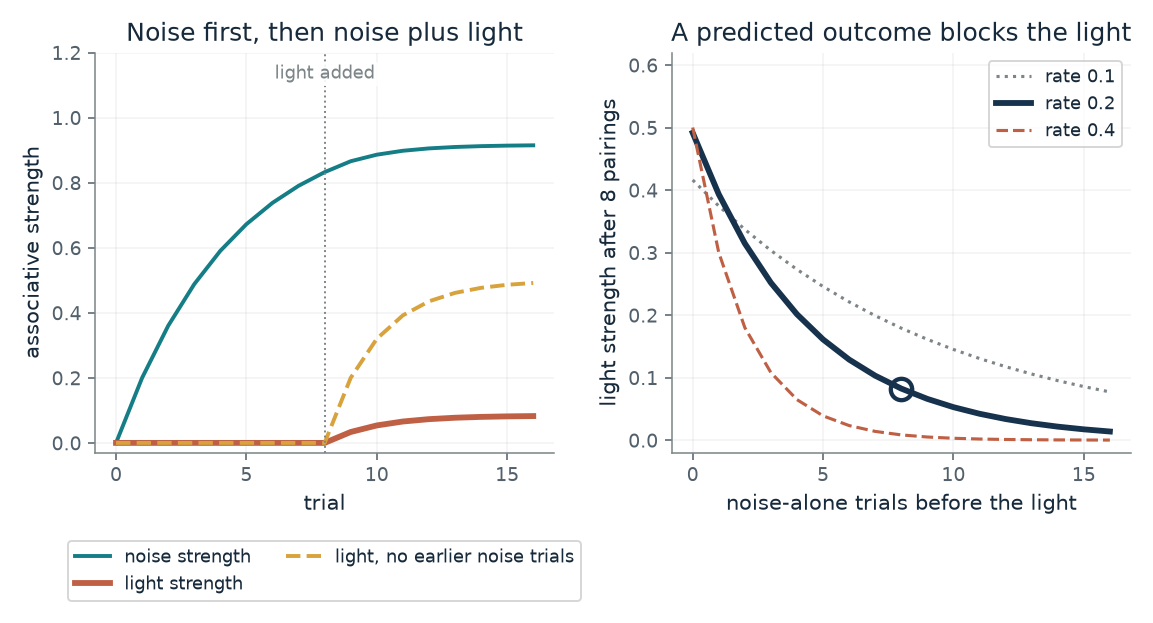

- **Light strength after 8 pairings:** 0.0825
- **Same, light and noise learned together:** 0.492
- **Gap left for learning at the first pairing:** 0.168
- **Light as a share of the together value:** 0.168

After 8 noise-alone trials the noise holds strength 0.832, leaving a gap of 0.168 for the light to learn from. After 8 pairings the light has strength 0.0825, against 0.492 when light and noise were learned together.

Each cue present gains rate x (1 - combined strength) = 0.2 x gap per trial. Noise alone: strength = 1 - (1 - 0.2)^8 = 0.832. First pairing gap = 0.168. Light after 8 pairings = gap x (1 - (1 - 2 x 0.2)^8) / 2 = 0.0825.

In [4]:
figure, values, explanation = blocking_picture(**{'preliminary': 8, 'rate': 0.2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a cue added to a predicted outcome teach so little?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Noise-alone trials before the light = 16, Learning-rate constant (c) = 0.2: After 16 noise-alone trials at rate 0.2 the noise holds strength 0.972, the gap left is 0.028, and the light gains only about 0.014 in 8 pairings, against about 0.49 when light and noise are learned together. Kamin's rats showed the same direction (a ratio of .45 near no effect, against .05).

**Takeaway:** When the outcome is already predicted, the gap that drives learning is nearly zero, so a new cue is learned poorly.

**Why it matters:** A learner driven by error learns about a cue only to the extent that the cue is needed to explain a surprise. This also explains why redundant signals can be ignored.

**In brains and behavior:** In 2013 rats were given a laser pulse at reward time to switch on dopamine cells during the pairing of sound plus light; they then responded more to the light. This supports sufficiency in that task, not necessity, and the cells' firing was not measured.

**In machines:** The rule is the same error-driven update as in the previous cards, applied to several cues at once. It is a specification for a learner, and a model of behavior for animals.

**Where it applies:** Both cues have the same learning rate and the outcome is the same size on every trial. The rule shows what blocking would look like, which does not show that rats follow it. The link joins two models of learning, not a brain and a machine.

**Check your understanding:** If the noise has reached strength 1 exactly, what does the light gain on the first pairing?

<details><summary>Show the answer</summary>

The gap is 1 minus 1, which is zero, so the light gains nothing, however many pairings follow.

</details>

*Source: Chapter 14, Blocking: rats learned little from a cue added to a predicted outcome. The rule is the Rescorla and Wagner update as the chapter states it (each cue present learns a share of the gap between the outcome and the combined strength of all cues present). The learning rates and trial counts follow the chapter's design (16 noise trials, then 8 pairings, against 8 pairings from the start); the rates are made up. Kamin's reported median suppression ratios, .05 for light and noise learned together and .45 for noise first, are context and are not fitted: a strength is not a suppression ratio.*

## C14-D04: How does a learner revise the value of an action?

Moving left is valued at 2, earns 1, and the best next option is valued at 3. What is the new estimate?

The target is what the experience suggests the action is worth: the reward now plus the discounted value of the best next option. The estimate is nudged toward it by a share alpha. A discount of zero ignores the future, and a learning rate of one replaces the estimate with the target.

$$
Q_{\mathrm{new}}(s,a)=Q_{\mathrm{old}}(s,a)+\alpha\left[r+\gamma\max_{a'}Q_{\mathrm{old}}(s',a')-Q_{\mathrm{old}}(s,a)\right]
$$

**Symbols:** Q: estimated total future reward from taking an action in a situation; r: the reward just received; gamma: the discount on later rewards; max Q(s', a'): the best estimated value available in the next situation, zero if the task ends; alpha: learning rate, the share of the gap used for the correction

**Predict before looking:** With a discount of 0.9 and a rate of 0.5, predict the new estimate, then predict what happens to it when the next situation ends the task.

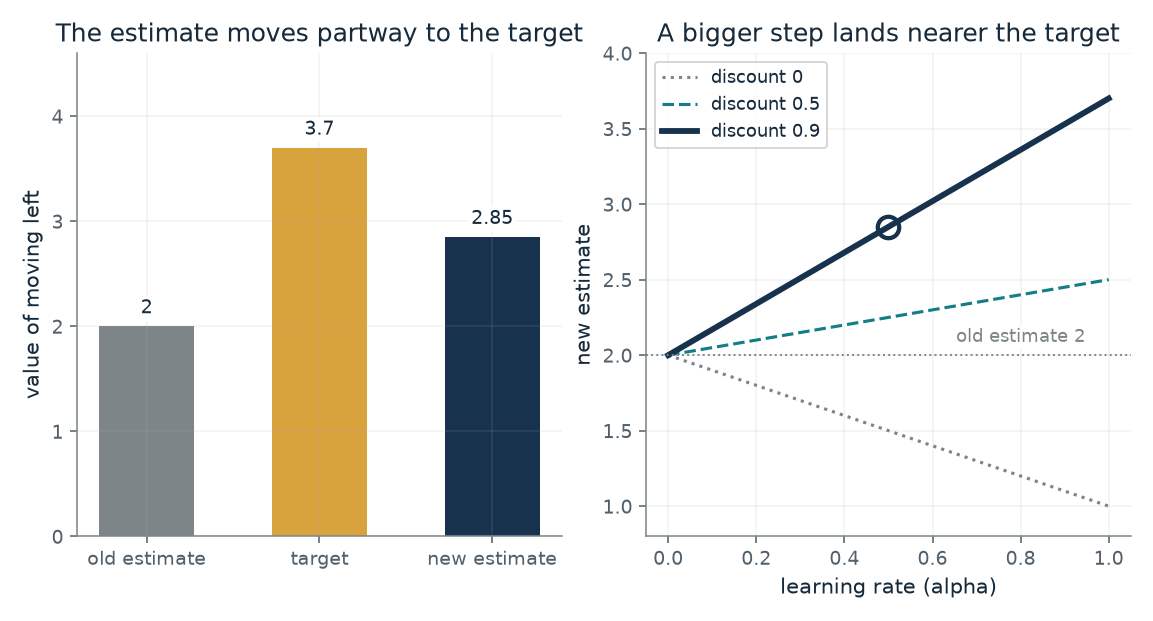

- **Target:** 3.7
- **Gap, target minus estimate:** 1.7
- **New estimate:** 2.85
- **Share of the gap closed:** 0.5

The target is 3.7 (best next value 3 is counted), so the estimate of 2 moves a share 0.5 of the gap 1.7 to 2.85. A learning rate of 1 would jump all the way to the target.

Target = r + gamma x max Q(next) = 1 + 0.9 x 3 = 3.7. New = 2 + 0.5 x (3.7 - 2) = 2.85.

In [5]:
figure, values, explanation = q_picture(**{'alpha': 0.5, 'gamma': 0.9, 'ends_task': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a learner revise the value of an action?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Learning rate (alpha) = 0.5, Discount (gamma) = 0.9, The next situation ends the task (1 = yes) = 1: If the next situation ends the task, the target is just the reward, 1, and the estimate falls from 2 to 1.5. In the continuing case the target is 3.7 and the estimate rises to 2.85.

**Takeaway:** The estimate moves a share alpha of the way toward a target built from the reward and the best next value.

**Why it matters:** Action values let a learner choose between actions from experience, without a model of the world. The discount sets how much later rewards count.

**In machines:** This is a specification of the update. A reward is a number the task supplies. A related update, with a neural network estimating the values from game images, was the 2015 Atari learner.

**Where it applies:** A table of action values for one situation and action. The target counts the best next action even when the learner explores and tries something else. A deep Q-network learns toward a related target by training a network, not by replacing a table entry.

**Check your understanding:** With estimate 2, reward 1, best next value 3, discount 0.5 and rate 0.5, what is the new estimate?

<details><summary>Show the answer</summary>

The target is 1 + 0.5 x 3 = 2.5, and the new estimate is 2 + 0.5 x (2.5 - 2) = 2.25.

</details>

*Source: Chapter 14, Learning which action to take. Book formula with the chapter's constructed numbers (estimate 2, reward 1, best next value 3, discount 0.9, rate 0.5, giving a target of 3.7 and a new estimate of 2.85). Not game results.*

## C14-D05: Why does trusting the best-looking estimate overrate an action?

If every action is equally good but the estimates are noisy, how much does the best-looking one overshoot?

Each estimate errs up or down with equal chance. Picking the largest picks, among other things, the one that erred upward the most. The more options there are, the more likely one of them has a large upward error, so the best-looking estimate rises even though no action is truly better.

$$
\mathbb{E}\left[\max_a \hat Q(a)\right]=\sigma\,\mathbb{E}\left[\max_{i\le n}Z_i\right]\ \ge\ 0,\qquad Z_i\sim\mathcal N(0,1)
$$

**Symbols:** Q-hat(a): a noisy but unbiased estimate of the action's value, whose true value is 0 for every action here; sigma: the standard deviation of the estimate's noise; n: the number of equally good actions; Z_i: independent standard normal draws

**Predict before looking:** Estimates are unbiased, so predict whether the best-looking of two equal actions is overestimated, and by roughly what fraction of the noise sd.

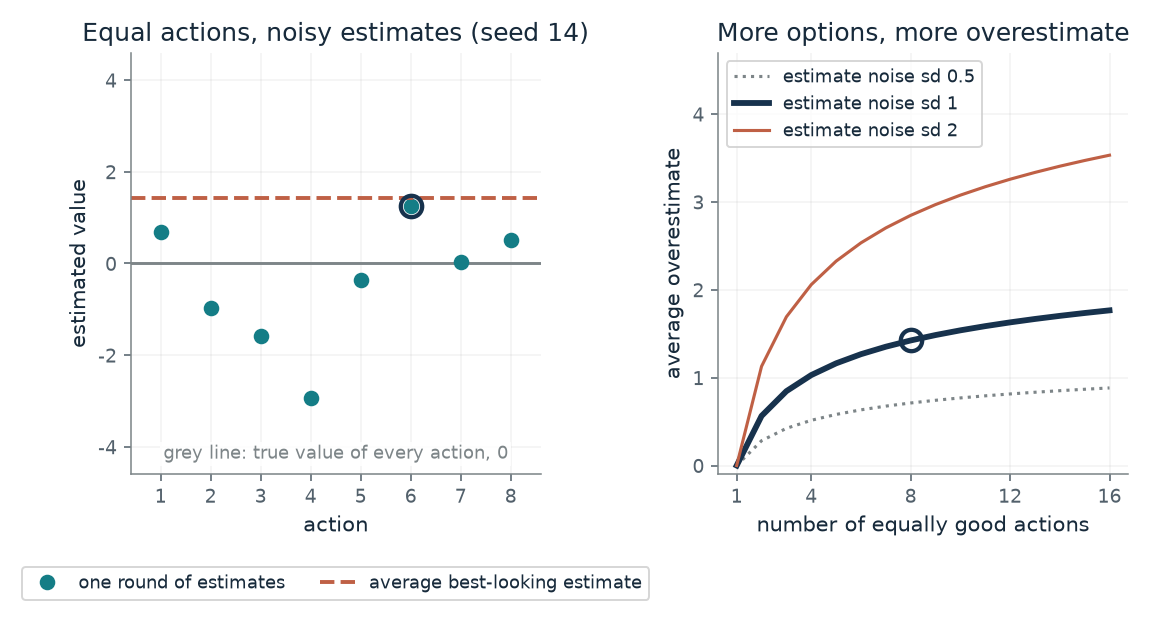

- **Average best-looking estimate:** 1.42
- **True value of the action it picks:** 0
- **Overestimate in units of the noise sd:** 1.42
- **This round's best-looking estimate:** 1.25

With 8 equally good actions and estimate noise sd 1, the best-looking one is overestimated by 1.42 on average, though the estimates themselves are unbiased. The upward bias comes from picking the maximum of noisy numbers, and it grows with the number of options.

Average of the largest of 8 standard normal draws = 1.42 (numerical integration of x n phi(x) Phi(x)^(n-1)). Times noise sd 1 = 1.42. For 2 actions the exact value is sd / sqrt(pi) = 0.564.

In [6]:
figure, values, explanation = overestimate_picture(**{'n_actions': 8, 'noise_sd': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does trusting the best-looking estimate overrate an action?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of equally good actions = 2, Noise sd of each estimate = 1.0: With two equal actions the best-looking estimate overshoots by sd / sqrt(pi), about 0.56 of the noise sd, even though each estimate alone is unbiased. Move to 16 actions and it overshoots by about 1.77 sd.

**Takeaway:** The maximum of unbiased noisy estimates is biased upward, more so with more options and more noise.

**Why it matters:** A learner that bases its target on the best-looking next estimate inherits this bias. The score it is given is not the cause; the maximum is.

**In machines:** Q-learning's target takes a maximum over estimated values, which is why the chapter notes the 2015 network sometimes overestimates action values. This picture is the arithmetic of a maximum, not a test of that network.

**Where it applies:** Independent, unbiased, normally distributed noise of the same size for every action, and equal true values. Real estimates are neither independent nor equally noisy.

**Check your understanding:** For 2 actions with noise sd 2, what is the average overestimate of the best-looking one?

<details><summary>Show the answer</summary>

2 / sqrt(pi) = 1.13.

</details>

*Source: Chapter 14, Atari: 75 percent of a human tester's gain on 29 of 49 games, 0.0 percent on Montezuma's Revenge. The chapter says that trusting the best-looking estimate can overrate an action, and that van Hasselt and colleagues found the 2015 network sometimes overestimates action values in some games. This card is the companion's own constructed illustration of the statistical reason, with made-up noise and equally good actions. It is not a measurement of any network, and the size of the real overestimate is not shown here.*

## C14-D06: How good is a game score, counted over random play?

On Frostbite the 2015 network scored 328.3, random play 65.2 and a human tester 4,335. What share of the human gain is that?

The gain over random play is the part of the score that was learned. Dividing the network's gain by the human tester's gain gives the share. Frostbite is one of the weak games; Montezuma's Revenge was 0.0 percent.

$$
\text{share}=\frac{\text{score}-\text{random}}{\text{human}-\text{random}}
$$

**Symbols:** score: the learner's game score; random: the score of random play, 65.2 on Frostbite; human: the professional tester's score, 4,335 on Frostbite

**Predict before looking:** Predict, before moving the slider, whether 328.3 is above or below a quarter of the human gain on Frostbite, then find the score needed for 75 percent.

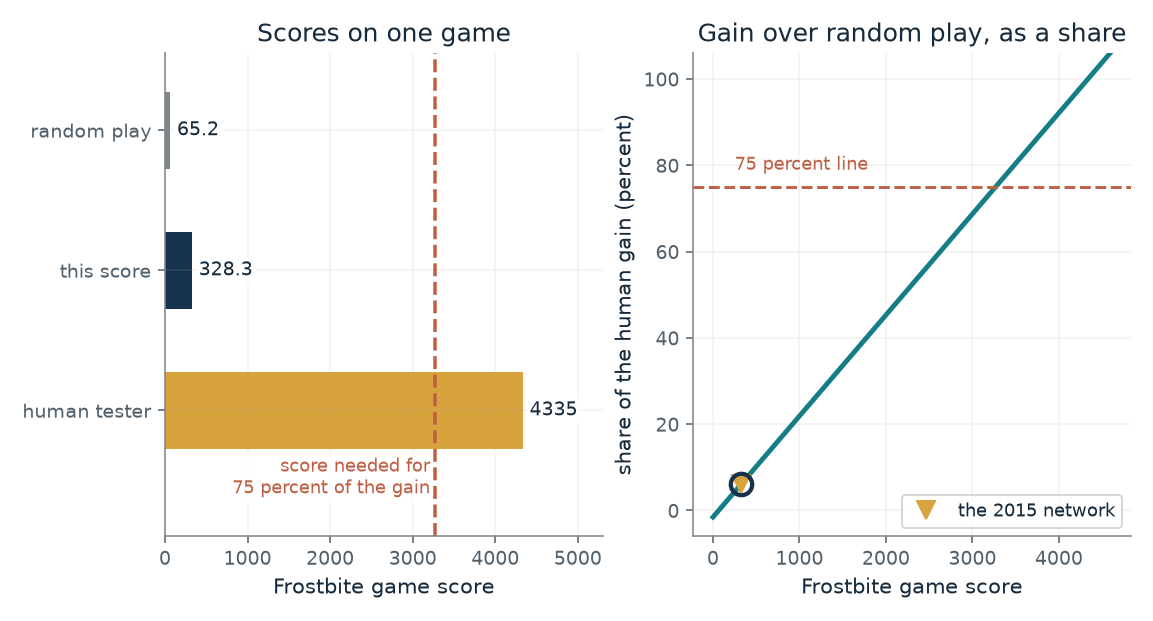

- **Gain over random play:** 263.1
- **Human gain over random play:** 4269.8
- **Share of the human gain (percent):** 6.16
- **Reaches 75 percent:** no

The 2015 network's Frostbite score of 328.3 is a gain of 263.1 over random play, 6.16 percent of the human tester's 4269.8. Reaching 75 percent on this game takes a score of 3268.

Gain = 328.3 - 65.2 = 263.1. Human gain = 4335 - 65.2 = 4269.8. Share = 263.1 / 4269.8 = 0.06162. Score for 75 percent = 65.2 + 0.75 x 4269.8 = 3267.55.

In [7]:
figure, values, explanation = frostbite_picture(**{'score': 328.3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How good is a game score, counted over random play?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Frostbite score (328.3 is the network's) = 3267.55: A score of 3267.55 is exactly 75 percent of the human gain on Frostbite: 65.2 + 0.75 x 4269.8. The network's 328.3 is far below that, at 6.2 percent.

**Takeaway:** Counted over random play, the network's Frostbite gain is 6.2 percent of the human gain, though it reached 75 percent on 29 of 49 games.

**Why it matters:** An average over games hides weak ones. Subtracting random play keeps a lucky guesser from looking skilled.

**In machines:** Each network used the same design and settings but trained from scratch on one game. The score is a stand-in for the goal, not the goal.

**Where it applies:** Gains are counted over random play so that only what was learned beyond guessing counts. A different network was trained on each game, so this is 49 trained networks, not one network that learned 49 games. Rewards were clipped to plus 1, minus 1 or zero, which hid differences in size. The study did not show that the score stands for what a person wants.

**Check your understanding:** A hypothetical Frostbite score of 2,200: what share of the human gain is it?

<details><summary>Show the answer</summary>

The gain is 2200 - 65.2 = 2134.8, and 2134.8 / 4269.8 is about 0.5, or 50 percent.

</details>

*Source: Chapter 14, Atari: 75 percent of a human tester's gain on 29 of 49 games, 0.0 percent on Montezuma's Revenge. Reported result from Mnih and colleagues (2015), as quoted in the chapter: Frostbite scores of 65.2, 328.3 and 4,335, and that the networks reached at least 75 percent of the tester's gain on 29 of 49 games. The companion's arithmetic gives the gains and shares. Scores other than 328.3 on the slider are hypothetical, to show what each share would take.*

## C14-D07: Why would many forecasting channels have different reversal points?

If some channels weigh good news more and others bad news, where does each settle, and which reward sizes flip its sign?

A channel stops changing when the pull from rewards above its forecast balances the pull from rewards below it, each weighted by its optimism. A balanced channel (0.5) settles at the average reward. An optimistic channel needs a larger reward before the news counts as good, so its reversal point is higher.

$$
v\leftarrow v+\eta\,\tau\,(r-v)\ \ (r>v),\qquad v\leftarrow v+\eta\,(1-\tau)\,(r-v)\ \ (r<v)
$$

**Symbols:** v: the channel's forecast, which is also its reversal point; tau: the channel's optimism: the weight on good news, between 0 and 1; eta: a small step size (0.02 here, made up); r: the reward delivered

**Predict before looking:** With seven equally likely reward sizes, predict which pair of sizes a channel with optimism 0.1 flips between, and one with optimism 0.9.

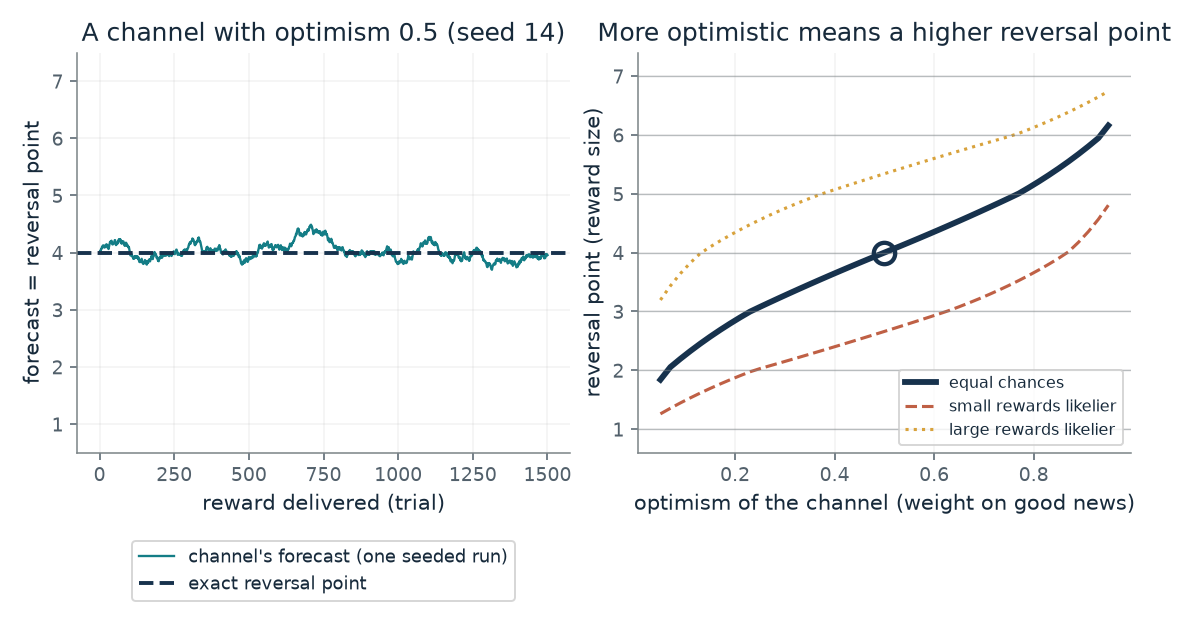

- **Reversal point (exact):** 4
- **Falls between reward sizes:** 4 and 5
- **Average reward:** 4
- **Last 500 trials of the run:** 3.94

A channel that weighs good news 0.5 and bad news 0.5 settles where rewards above its forecast and below it balance, at 4. Rewards larger than 4 give it a positive error and smaller ones a negative error, so its reversal point sits between sizes 4 and 5.

The forecast stops moving when 0.5 x E[(r - v) above zero] = 0.5 x E[(v - r) above zero]. Solving gives v = 4. The seeded run averaged 3.94 over its last 500 trials. At optimism 0.5 the point is the average reward, 4.

In [8]:
figure, values, explanation = channel_picture(**{'tau': 0.5, 'distribution': 'equal chances'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why would many forecasting channels have different reversal points?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Optimism of the channel (tau) = 0.9, Chances of the seven reward sizes (constructed) = equal chances: With equal chances, an optimistic channel (0.9) settles at about 5.7, between sizes 5 and 6, while a pessimistic one (0.1) settles at about 2.3, between sizes 2 and 3. A channel at 0.5 settles at the average reward, 4.

**Takeaway:** Channels that weigh good and bad news differently settle at different forecasts, so each flips sign at a different reward size.

**Why it matters:** Together the channels trace out the spread of possible rewards, not only the average. That is the prediction machine learning made first, which the 2020 study then tested.

**In brains and behavior:** In the 2020 reanalysis, 40 cells from a handful of mice had substantially different reversal points, and the pattern held when the trials were split in half at random. The evidence is observational and model-dependent, and the mathematics of a brain is a model.

**In machines:** A distributional learner keeps many forecasts with different asymmetries. Together they describe a distribution of rewards instead of one average.

**Where it applies:** Each channel follows its own error with asymmetric weights, and rewards are drawn independently from a fixed pattern. A close agreement with data would show consistency with this account, not that dopamine cells run this rule. The recordings were gathered for another purpose, the mice were few, and there are no human data.

**Check your understanding:** For equal chances of sizes 1 to 7, what is the reversal point of a channel with optimism 0.5?

<details><summary>Show the answer</summary>

The average reward, (1 + 2 + 3 + 4 + 5 + 6 + 7) / 7 = 4.

</details>

*Source: Chapter 14, Mouse dopamine cells flipped at different reward sizes, as a machine idea had predicted. The structure follows the chapter's description of the distributional idea: channels that give more weight to good news drift high and those that give more weight to bad news drift low. The seven reward sizes (1 to 7) and the three chance patterns are constructed, not the mice's water amounts. The reported result is the 2020 reanalysis the chapter describes: 40 dopamine cells recorded earlier by another team from a handful of mice, which the authors say had substantially different reversal points.*

## Bring it to your own question

Ask for the forecast, the outcome, what follows the situation, and the learning rate. Then choose the matching card: the prediction error and update for a single forecast, the chain card when value must travel back to an earlier cue, the blocking card when a new cue arrives with an outcome that is already predicted, the Q-learning card when the learner chooses actions, the overestimation card when it picks the best-looking estimate, and the score card when comparing a game score with random play and a human tester. State that a reward is a number the task supplies and that a good update rule does not solve exploration or say whether the score counts what a person wants.

Use the `mmi-ch14-learning-consequences` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.